# MotionProof AI
## Deliverable 2: Implementation and Early Evaluation

This notebook demonstrates the existing MotionProof AI inference pipeline using trained model checkpoints and processed PPG-DaLiA test data.

**Pipeline:** PPG → CNN heart-rate prediction → reliability classifier → fitted Q-learning investigation agent → ACCEPT or FLAG_UNRELIABLE.

The reference heart rate is used for evaluation, not as an input to the reliability decision.

### Reproducibility scope

This notebook reproduces inference for selected test windows and displays saved evaluation results. It does **not** retrain the models or independently regenerate the complete held-out evaluation.

Original training and experimentation notebooks:
- `setup.ipynb`
- `setup_2.ipynb`

The full training dataset is required to reproduce model training.


## 1. Environment and project configuration

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().resolve()

if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

assert (ROOT / "src").is_dir(), "Run from the project root or notebooks directory."

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.generate_validation_predictions import load_cnn, predict_cnn
from src.evaluation.reliability_features import extract_reliability_features
from src.evaluation.reliability_baseline import FEATURE_COLUMNS
from src.agents.fitted_q_inference import load_fitted_q_policy
from src.agents.investigation_environment import InvestigationEnvironment

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Project:", ROOT)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)


Project: /Users/apple/Documents/MotionProof-AI-VSCode
Python: 3.12.6
PyTorch: 2.15.0
Device: cpu


## 2. Verify the required files

In [2]:
required = [
    ROOT / "data/processed/test/S13.npz",
    ROOT / "checkpoints/ppg_cnn_best.pt",
    ROOT / "checkpoints/reliability_classifier_nonlinear_full.joblib",
    ROOT / "checkpoints/learned_policy_fitted_q_full.pt",
    ROOT / "results/metrics/final_test/test_policy_comparison.csv",
    ROOT / "results/metrics/final_test/test_policy_inputs_nonlinear.csv",
]

for file in required:
    print(("PASS" if file.is_file() else "MISSING"), file.relative_to(ROOT))

assert all(file.is_file() for file in required)


PASS data/processed/test/S13.npz
PASS checkpoints/ppg_cnn_best.pt
PASS checkpoints/reliability_classifier_nonlinear_full.joblib
PASS checkpoints/learned_policy_fitted_q_full.pt
PASS results/metrics/final_test/test_policy_comparison.csv
PASS results/metrics/final_test/test_policy_inputs_nonlinear.csv


## 3. Load processed PPG-DaLiA test data

In [3]:
with np.load(ROOT / "data/processed/test/S13.npz", allow_pickle=False) as data:
    ppg_windows = data["ppg"].copy()
    acc_windows = data["acc"].copy()
    reference_hr = data["hr"].copy()

assert ppg_windows.shape[1] == 512
assert acc_windows.shape[1:] == (256, 3)
assert len(ppg_windows) == len(acc_windows) == len(reference_hr)

print("PPG:", ppg_windows.shape)
print("Accelerometer:", acc_windows.shape)
print("Reference HR:", reference_hr.shape)


PPG: (4565, 512)
Accelerometer: (4565, 256, 3)
Reference HR: (4565,)


## 4. Load the trained models

In [4]:
cnn, mean, std = load_cnn(DEVICE)

classifier = joblib.load(
    ROOT / "checkpoints/reliability_classifier_nonlinear_full.joblib"
)

agent = load_fitted_q_policy(
    ROOT / "checkpoints/learned_policy_fitted_q_full.pt",
    device="cpu",
)

print("CNN: loaded")
print("Reliability classifier: loaded")
print("Fitted Q-learning agent: loaded")


CNN: loaded
Reliability classifier: loaded
Fitted Q-learning agent: loaded


## 5. Load saved prediction history

In [5]:
inputs = pd.read_csv(
    ROOT / "results/metrics/final_test/test_policy_inputs_nonlinear.csv"
)

print("Saved evaluation rows:", len(inputs))
print("Columns:", list(inputs.columns))

def get_history(subject, window):
    rows = inputs[
        (inputs["subject"] == subject)
        & (inputs["window_index"] < window)
    ].sort_values("window_index")

    return rows.tail(5)["cnn_predicted_hr"].tolist()


Saved evaluation rows: 13007
Columns: ['subject', 'window_index', 'cnn_predicted_hr', 'unreliable_probability', 'reference_hr', 'absolute_error', 'unreliable_target']


## 6. Run the complete inference pipeline

In [ ]:
# S13 window 2541 is the example shown in the D2 report (Fig. 3).
window = 2541
history = get_history(13, window)  # previous CNN predictions only, never reference HR

ppg = ppg_windows[window]
acc = acc_windows[window]

prediction = predict_cnn(model=cnn, ppg=ppg.reshape(1, -1), mean=mean, std=std, device=DEVICE)
predicted_hr = float(np.asarray(prediction).reshape(-1)[0])

features = extract_reliability_features(ppg.reshape(1, -1), acc.reshape(1, 256, 3))
feature_frame = pd.DataFrame(np.column_stack([features, [predicted_hr]]), columns=FEATURE_COLUMNS)
probability = float(classifier.predict_proba(feature_frame)[0, 1])

environment = InvestigationEnvironment(
    ppg_window=ppg,
    acc_window=acc,
    cnn_predicted_hr=predicted_hr,
    unreliable_probability=probability,
    previous_hr_predictions=history,
    budget=2,
)
result = agent.run(environment)

sample = {
    "subject": 13,
    "window": window,
    "predicted_hr": predicted_hr,
    "failure_probability": probability,
    "actions": result["actions"],
    "final_decision": result["final_decision"],
    "reference_hr": float(reference_hr[window]),  # evaluation only
}

print(f"S13 window {window}")
print(f"CNN heart rate:        {predicted_hr:.1f} BPM")
print(f"Failure probability:   {probability:.1%}")
print(f"Agent actions:         {' -> '.join(result['actions'])}")
print(f"Final decision:        {result['final_decision']}")
print(f"Reference HR (eval):   {sample['reference_hr']:.1f} BPM")
print(f"Absolute error (eval): {abs(predicted_hr - sample['reference_hr']):.1f} BPM")

S13 window 2541
CNN heart rate:        78.1 BPM
Failure probability:   22.5%
Agent actions:         CHECK_PPG -> ACCEPT
Final decision:        ACCEPT
Reference HR (eval):   79.8 BPM
Absolute error (eval): 1.7 BPM


## 7. Visualize the selected signal window

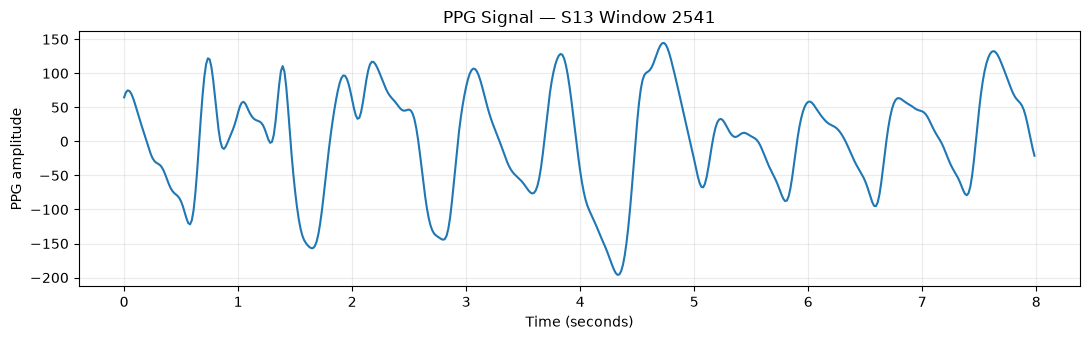

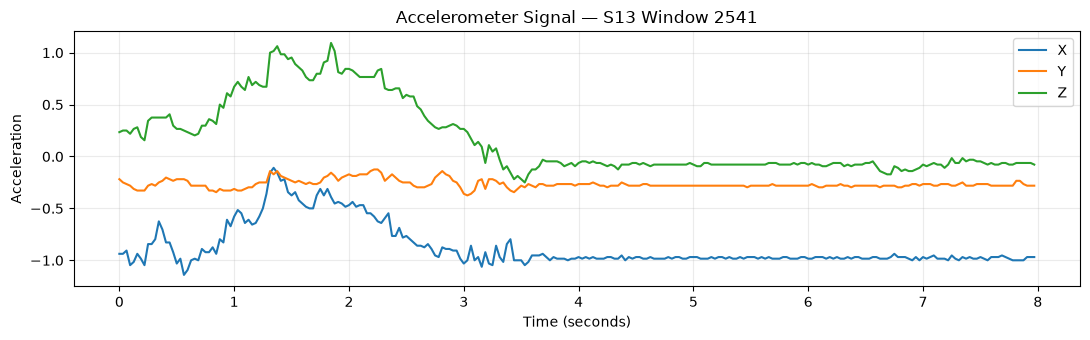

In [7]:
window_index = sample["window"]

ppg = ppg_windows[window_index]
acc = acc_windows[window_index]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(np.arange(len(ppg)) / 64, ppg)
ax.set(
    title=f"PPG Signal — S13 Window {window_index}",
    xlabel="Time (seconds)",
    ylabel="PPG amplitude",
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5))

for axis, name in enumerate("XYZ"):
    ax.plot(np.arange(len(acc)) / 32, acc[:, axis], label=name)

ax.set(
    title=f"Accelerometer Signal — S13 Window {window_index}",
    xlabel="Time (seconds)",
    ylabel="Acceleration",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Saved held-out evaluation results

The following results were generated by the project's existing evaluation pipeline and loaded from its saved CSV artifacts.

They are **not** recalculated by this notebook. Interpret them alongside the original evaluation scripts and experimental configuration.


In [8]:
comparison = pd.read_csv(
    ROOT / "results/metrics/final_test/test_policy_comparison.csv"
)

print("Saved policy comparison:")
display(comparison)

print("\nAvailable columns:")
print(list(comparison.columns))


Saved policy comparison:


,windows,accuracy,precision,recall,f1,specificity,false_positive_rate,false_negative_rate,true_positives,false_positives,true_negatives,false_negatives,average_investigations,average_reward,flag_rate,policy
0,13007,0.683324,0.261488,0.703437,0.381253,0.680086,0.319914,0.296563,1269,3584,7619,535,1.037288,-0.404182,0.373107,Fixed Rule
1,13007,0.642423,0.263813,0.881375,0.406078,0.603945,0.396055,0.118625,1590,4437,6766,214,0.957869,-0.395895,0.463366,Learned Fitted Q
2,13007,0.674022,0.232543,0.587029,0.333124,0.688030,0.311970,0.412971,1059,3495,7708,745,0.000000,-0.354771,0.350119,No Investigation



Available columns:
['windows', 'accuracy', 'precision', 'recall', 'f1', 'specificity', 'false_positive_rate', 'false_negative_rate', 'true_positives', 'false_positives', 'true_negatives', 'false_negatives', 'average_investigations', 'average_reward', 'flag_rate', 'policy']


## 9. Interpretation and limitations

MotionProof AI separates heart-rate estimation from prediction-reliability assessment.

The CNN predicts heart rate. The nonlinear classifier estimates unreliability probability. The fitted Q-learning agent may investigate PPG quality, motion artifacts, or prediction consistency before accepting or flagging a prediction.

**Limitations:**
- This demonstration uses trained checkpoints.
- Training data for S1–S12 is not included in this local demonstration.
- A classifier probability is not a guarantee of correctness.
- Agent decisions can produce false positives and false negatives.
- Held-out performance should be interpreted using precision, recall, F1, specificity, and investigation cost rather than a single metric.
- This system is a research prototype, not a clinical diagnostic device.

### Training and full evaluation

Refer to the original notebooks and scripts under `src/evaluation/`. Full training reproduction requires the original dataset, preprocessing configuration, and training environment.
